In [1]:
import numpy as np
# from pycbf.gpu import TabbedBeamformer
# from pycbf.cpu import TabbedBeamformer
import matplotlib.pyplot as plt
import pycbf.helpers as helpers
import pycbf.dataio as dio
from scipy.signal import hilbert, filtfilt, butter

from tqdm.notebook import tqdm

from time import time

In [69]:
# data = dio.loadHDF5asdict("channel_data_exvivo_bovine.h5")
data = dio.loadHDF5asdict("channel_data_patient.h5")

rf = data['rf']
dims = data['dims']
c0 = data['c0']
f0 = data['f0']

t = dims['t_sec']
xele = dims['xele_m']
steers = np.radians(dims['steer_deg'])

lam = c0/f0
b, a = butter(5, (1.0E6,4.5E6), btype='bandpass', fs=1/(t[1]-t[0]))
rf = filtfilt(b,a,rf,axis=-1)

In [70]:
def calc_coherence(subset):
    # subtract the mean of each aline
    submmu = subset - np.mean(subset, axis=0, keepdims=True)
    sig = np.std(subset, axis=0)
    n = len(sig)

    # caculate the lag-n coherence
    rhos = np.zeros(len(sig)-1)
    for lag in range(subset.shape[1]-1):
        cross = np.mean(submmu[:,:n-lag] * submmu[:,lag:], axis=0)
        rhos[lag] = np.mean(cross / (sig[:n-lag] * sig[lag:]))
    
    return rhos

def calc_lagn_coherence(subset, lag:int):
    submmu = subset - np.mean(subset, axis=0, keepdims=True)
    sig = np.std(subset, axis=0)
    n = len(sig)

    sig[sig<1E-10] = np.nan
    cross = np.mean(submmu[:,:n-lag] * submmu[:,lag:], axis=0)
    return np.nanmean(cross / (sig[:n-lag] * sig[lag:]))

In [71]:
sospeak = 1540

fnum = 0.8

dsfx = 2
dsfz = 2*dsfx

xout, zout = helpers.make_recon_grid_by_BW_2D(
    fnum = fnum,
    lam = lam,
    xmin = -10E-3,
    xmax =10E-3,
    zmin = 1E-3,
    zmax = 60E-3,
    BWx = 2,
    BWz = 2
)

# dz = (zout[-1]-zout[0])/len(zout)


# chunk = len(xout)//8
# xout = xout[chunk:-chunk]

dz = zout[1]-zout[0]
nkern = int(np.ceil(0.5 * lam / (dz)/2))

bfparams = helpers.make_tabs_and_apods_2D(
    steers=steers,
    r0 = 0,
    ctx=c0,
    cm=sospeak,
    xele=xele,
    xout=xout,
    zout=zout,
    fnum=fnum
)

apodrx_coherence = bfparams['apodrx'].reshape(-1, len(xout), len(zout))

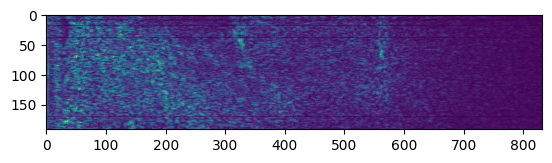

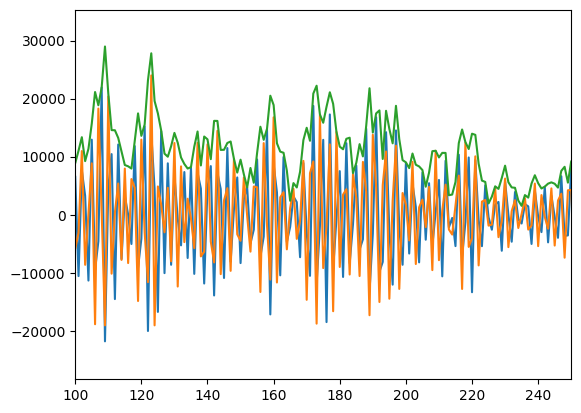

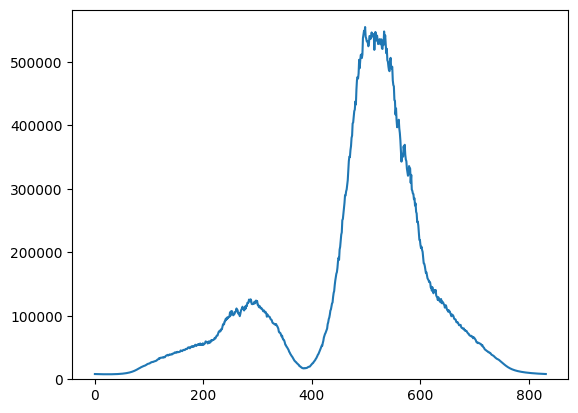

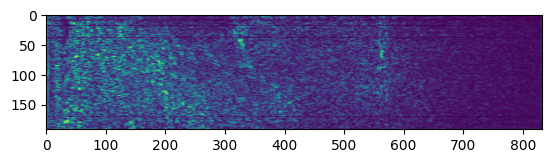

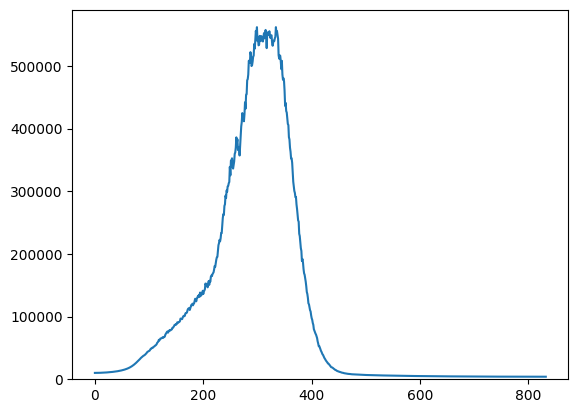

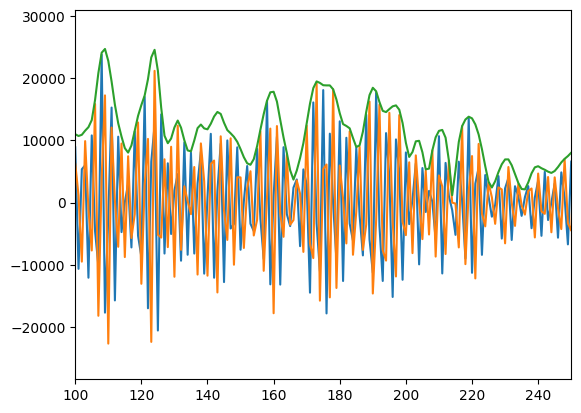

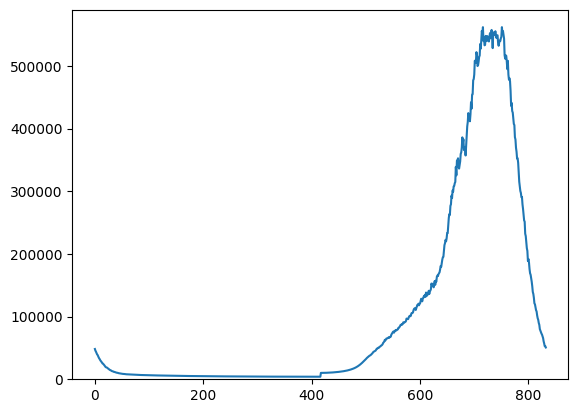

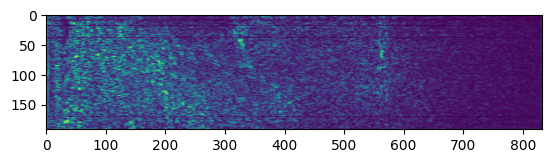

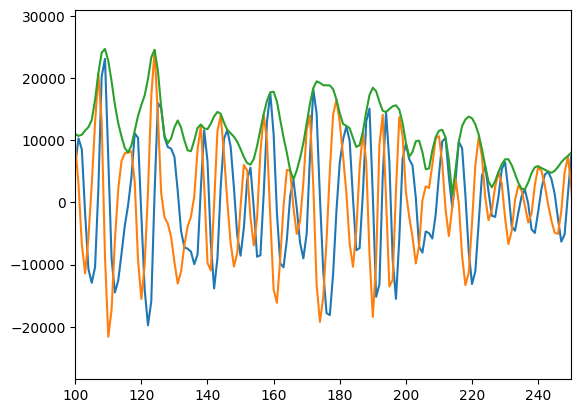

In [72]:
rfsub_iq = rf[1,:,:,::2] + 1j * rf[1,:,:,1::2]

plt.figure()
plt.imshow(np.abs(rfsub_iq[5]))
plt.show()

plt.figure()
plt.plot(rfsub_iq[5,86,:].real)
plt.plot(rfsub_iq[5,86,:].imag)
plt.plot(np.abs(rfsub_iq[5,86,:]))
plt.xlim(100,250)
plt.show()

spec = np.abs(np.fft.fft(rfsub_iq, axis=-1))
plt.figure()
plt.plot(np.mean(spec, axis=(0,1)))
plt.ylim(0, None)

rfsub_iq = np.fft.ifft(np.fft.rfft(rf[1], axis=-1), axis=-1)

plt.figure()
plt.imshow(np.abs(rfsub_iq[5]))
plt.show()

spec = np.abs(np.fft.fft(rfsub_iq, axis=-1))
plt.figure()
plt.plot(np.mean(spec, axis=(0,1)))
plt.ylim(0, None)

plt.figure()
plt.plot(rfsub_iq[5,86,:].real)
plt.plot(rfsub_iq[5,86,:].imag)
plt.plot(np.abs(rfsub_iq[5,86,:]))
plt.xlim(100,250)
plt.show()

rfsub_iq = np.fft.ifft(np.fft.ifftshift(np.fft.rfft(rf[1], axis=-1), axes=-1), axis=-1)

spec = np.abs(np.fft.fft(rfsub_iq, axis=-1))
plt.figure()
plt.plot(np.mean(spec, axis=(0,1)))
plt.ylim(0, None)

plt.figure()
plt.imshow(np.abs(rfsub_iq[5]))
plt.show()

plt.figure()
plt.plot(rfsub_iq[5,86,:].real)
plt.plot(rfsub_iq[5,86,:].imag)
plt.plot(np.abs(rfsub_iq[5,86,:]))
plt.xlim(100,250)
plt.show()

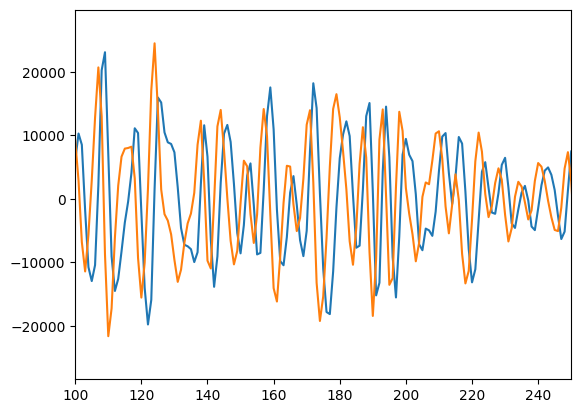

In [73]:
plt.figure()
plt.plot(rfsub_iq[5,86,:].real)
plt.plot(rfsub_iq[5,86,:].imag)
plt.xlim(100,250)
plt.show()

In [74]:
tautx = bfparams['tautx']
taurx = bfparams['taurx']
apodrx = bfparams['apodrx']
apodtx = bfparams['apodtx']

dt = (t[2]-t[0])
imsiq = []
for itx in range(tautx.shape[0]):
    imiq = 0
    print(itx)

    for irx in range(taurx.shape[0]):
        tautot = tautx[itx] + taurx[irx]
        tind = np.array(np.round((tautot - t[0]) / dt), dtype=np.int64)
        tind_mask = (tind < 0) | (tind >= rfsub_iq.shape[-1])
        tind[tind_mask] = 0

        imiq += (1.0-tind_mask) * apodtx[itx,:] * apodrx[irx,:] * rfsub_iq[itx,irx,tind] * np.exp(2j*np.pi*f0*(tautot-0*tind*dt-t[0]))

    imsiq.append(imiq)
imsiq = np.array(imsiq)

0
1
2
3
4
5
6
7
8
9
10


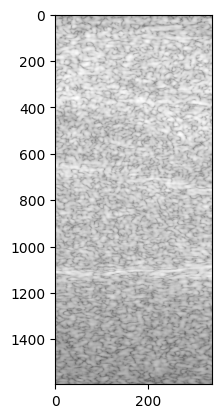

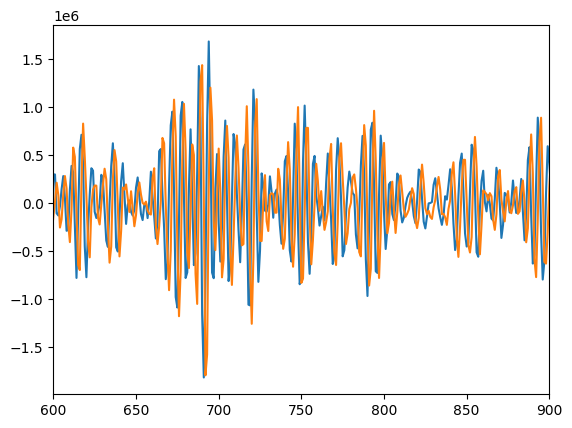

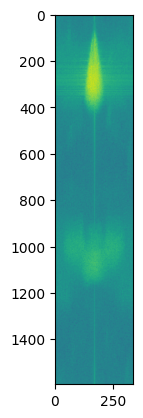

In [75]:
imiq_das = np.sum(imsiq,axis=0).reshape(len(xout), len(zout)).T
env = np.abs(imiq_das)
logged = 20*np.log10(env/np.percentile(env, 99))
plt.figure()
plt.imshow(logged, aspect=1/2, vmin=-70, vmax=5, cmap='gray')
plt.show()

plt.figure()
plt.plot(imiq_das[:,imiq_das.shape[1]//2].real)
plt.plot(imiq_das[:,imiq_das.shape[1]//2].imag)
plt.xlim(600,900)
plt.show()

env = np.abs(np.fft.fftshift(np.fft.fft2(imiq_das),axes=1))
logged = 20*np.log10(env/np.percentile(env,99))
plt.figure()
plt.imshow(logged)
plt.show()

In [76]:
imiq_das.shape

(1595, 339)

In [77]:
IQ_DMAS = 0
ntx = tautx.shape[0]
for ilag in range(1,ntx):
    temp = imsiq[ilag:]*imsiq[:(ntx-ilag)]
    IQ_DMAS += np.sum(np.sqrt(np.abs(temp)) * np.exp(1j*np.angle(temp)), axis=0)
IQ_DMAS = IQ_DMAS.reshape(len(xout), len(zout)).T

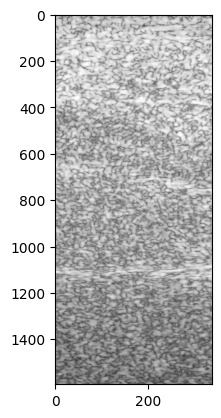

In [78]:
env = np.abs(IQ_DMAS)
logged = 20*np.log10(env/np.percentile(env, 99))

plt.figure()
plt.imshow(logged, aspect=1/2, vmin=-70, vmax=5, cmap='gray')
plt.show()

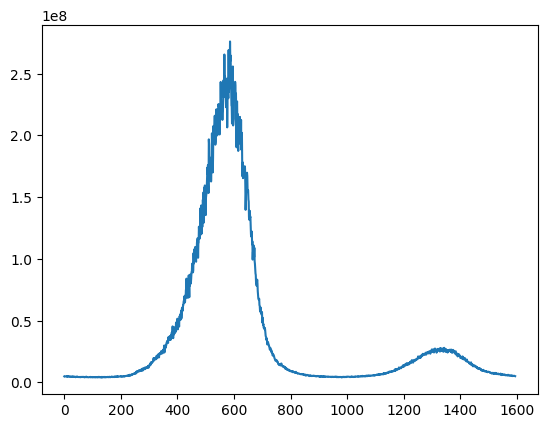

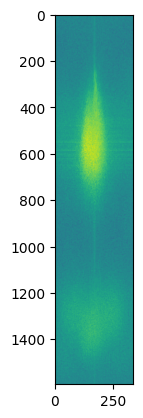

In [79]:
spec = np.fft.fft(IQ_DMAS, axis=0)

plt.figure()
plt.plot(np.mean(np.abs(spec), axis=1))

env = np.abs(np.fft.fftshift(np.fft.fft2(IQ_DMAS),axes=1))
logged = 20*np.log10(env/np.percentile(env,99))
plt.figure()
plt.imshow(logged)
plt.show()

In [80]:
b, a = butter(5, (1E6,8E6), btype='bandpass', fs=1/(t[1]-t[0]))
imsiq_filt = filtfilt(b,a,imsiq,axis=-1)

IQ_DMAS = 0
ntx = tautx.shape[0]
for ilag in range(1,ntx):
    temp = imsiq_filt[ilag:]*imsiq_filt[:(ntx-ilag)]
    IQ_DMAS += np.sum(np.sqrt(np.abs(temp)) * np.exp(1j*np.angle(temp)), axis=0)
IQ_DMAS = IQ_DMAS.reshape(len(xout), len(zout)).T

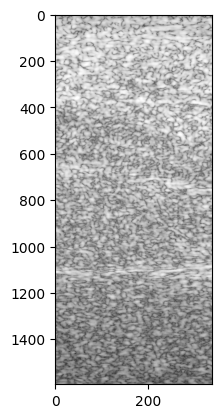

In [81]:
env = np.abs(IQ_DMAS)
logged = 20*np.log10(env/np.percentile(env, 99))

plt.figure()
plt.imshow(logged, aspect=1/2, vmin=-70, vmax=5, cmap='gray')
plt.show()

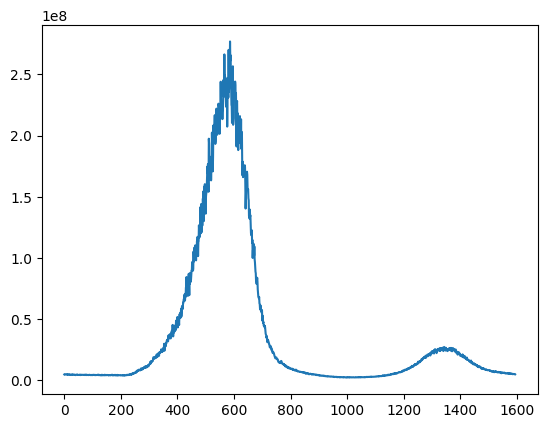

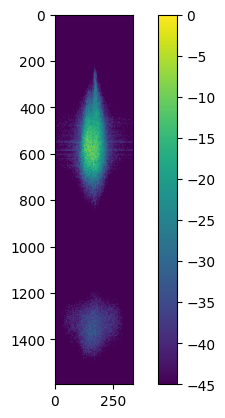

In [82]:
spec = np.fft.fft(IQ_DMAS, axis=0)

plt.figure()
plt.plot(np.mean(np.abs(spec), axis=1))

env = np.abs(np.fft.fftshift(np.fft.fft2(IQ_DMAS),axes=1))
logged = 20*np.log10(env/np.max(env))
plt.figure()
plt.imshow(logged, vmin=-45, vmax=0)
plt.colorbar()
plt.show()

In [83]:
tautx = bfparams['tautx']
taurx = bfparams['taurx']
apodrx = bfparams['apodrx']
apodtx = bfparams['apodtx']

dt = (t[2]-t[0])
imsiq_txrx = []
for itx in range(tautx.shape[0]):
    imiq = 0
    print(itx)

    imsiq_tx = []

    for irx in range(taurx.shape[0]):
        tautot = tautx[itx] + taurx[irx]
        tind = np.array(np.round((tautot - t[0]) / dt), dtype=np.int64)
        tind_mask = (tind < 0) | (tind >= rfsub_iq.shape[-1])
        tind[tind_mask] = 0

        imsiq_tx.append((1.0-tind_mask) * apodtx[itx,:] * apodrx[irx,:] * rfsub_iq[itx,irx,tind] * np.exp(2j*np.pi*f0*tautot))

    imsiq_txrx.append(imsiq_tx)
imsiq_txrx = np.array(imsiq_txrx)

0
1
2
3
4
5
6
7
8
9
10


In [84]:
imsiq_txrx = np.array(imsiq_txrx)

In [85]:
imsiq_txrx.shape

(11, 192, 540705)

In [86]:
imsiq_rx = np.sum(imsiq_txrx, axis=0)
imsiq_rx_ssr = np.sqrt(np.abs(imsiq_rx)) * np.exp(1j*np.angle(imsiq_rx))

In [95]:
IQ_DMAS = 0
nlag = 16
for ilag in range(1,nlag):
    IQ_DMAS += np.sum(imsiq_rx_ssr[ilag:]*imsiq_rx_ssr[:imsiq_rx.shape[0]-ilag], axis=0)
IQ_DMAS = IQ_DMAS.reshape(len(xout), len(zout)).T

IQ_DMAS = np.sum(np.sqrt(np.abs(imsiq_txrx)) * np.exp(1j*np.angle(imsiq_txrx)), axis=(0,1))**2 - np.sum(np.abs(imsiq_txrx) * np.exp(2j*np.angle(imsiq_txrx)), axis=(0,1))
IQ_DMAS = IQ_DMAS.reshape(len(xout), len(zout)).T

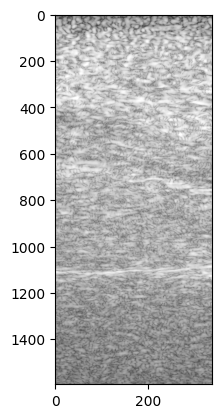

In [96]:
env = np.abs(IQ_DMAS)
logged = 20*np.log10(env/np.percentile(env, 99))

plt.figure()
plt.imshow(logged, aspect=1/2, vmin=-70, vmax=5, cmap='gray')
plt.show()

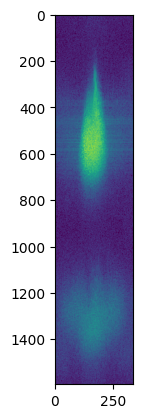

In [89]:
FFT = np.fft.fftshift(np.fft.fft2(IQ_DMAS), axes=1)

logged = 20*np.log10(np.abs(FFT))
logged -= np.max(logged)
plt.figure()
plt.imshow(logged, vmin=-60)

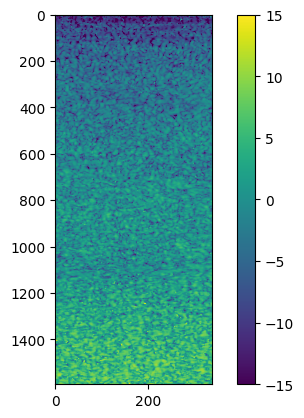

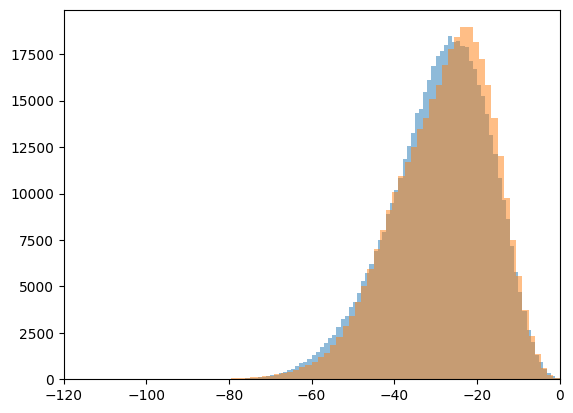

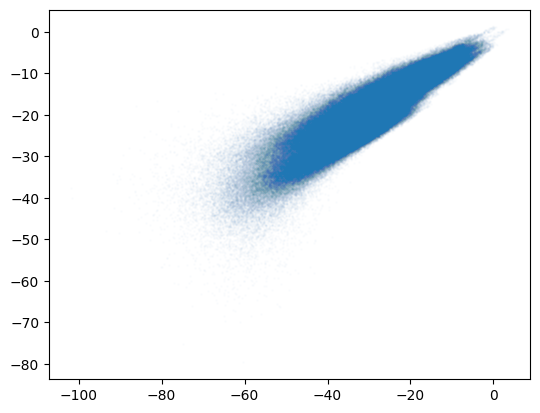

In [90]:
env_dmas = np.abs(IQ_DMAS)
logged_dmas = 20*np.log10(env_dmas/np.percentile(env_dmas, 99.99))

env_das = np.abs(imiq_das)
logged_das = 20*np.log10(env_das/np.percentile(env_das, 99.99))

scale = 1.5
plt.figure()
plt.imshow(logged_dmas-scale*logged_das, vmin=-15, vmax=15, aspect=1/2)
plt.colorbar()
plt.show()

plt.figure()
dB_bins = np.linspace(-100, 0, 101)
counts, _ = np.histogram(logged_dmas.flatten(), bins=dB_bins)
plt.stairs(counts, dB_bins, fill=True, alpha=0.5)
counts, _ = np.histogram(logged_das.flatten(), bins=dB_bins)
plt.stairs(counts/scale, scale*dB_bins, fill=True, alpha=0.5)
plt.xlim(-120, 0)
plt.show()

plt.figure()
plt.scatter(logged_dmas.flatten(), logged_das.flatten(), s=4, marker='.', alpha=0.01)
plt.gca().set_aspect(1)
plt.show()